## scMAVERICS - snRNAseq processing

This tutorial runs through taking the output of Cellbender (which should be run outside of a notebook) for a handful of samples and integrate the samples into a cell type annotated object. If the dataset in question is only transcriptomics, not multiomics, this analysis should be sufficent.

This section borrows heavily from the [scanpy](https://scanpy.scverse.org/en/1.12.x/) (version 1.11.5) introduction tutorial, with modifications made for incorporating packages
- [scVI](https://scvi-tools.org/) (version 1.4.2)
- [decoupler](https://decoupler.scverse.org/en/stable/) (version 2.1.6)
- [scrublet](https://github.com/swolock/scrublet)

This notebook and all others, can be created from the instructions [here](https://github.com/NIH-CARD/scMAVERICS/tree/main#local-environment)

## Package and data loading

In [1]:
# Import standard python packages
import numpy as np
import pandas as pd

# Plotting packages
import matplotlib.pyplot as plt
import seaborn as sns

# Specialized single cell packages
import scanpy as sc
import decoupler as dc
import scvi

### Define working and data directories

In [2]:
data_dir = '/data/CARD_singlecell/Brain_atlas/SN_Multiome/'
work_dir = '/data/CARD_singlecell/SN_atlas/' 

### Load metadata

As stated before, metadata should be imported, for visualizing parameters, 

In [3]:
metadata_df = pd.read_csv(work_dir + 'input/metadata.csv')
metadata_df

,Sample_ID,Use_batch,Age,PMI,Sex,Brain_bank,Primary Diagnosis
0,6178,6,68,22.5,Male,Human Brain and Spinal Fluid Resource Center,control
1,3284,1,78,11.5,Female,Human Brain and Spinal Fluid Resource Center,control
2,6384,3,50,22.3,Female,Human Brain and Spinal Fluid Resource Center,PD
3,5638,3,77,19.3,Male,Human Brain and Spinal Fluid Resource Center,PD


### Define parameters

In [4]:
# Define keys
sample_key = 'Sample_ID'
batch_key = 'Use_batch'

# Define list of samples
samples = metadata_df[sample_key]
batches = metadata_df[batch_key]

# Cell cycle file
cell_cycle_gene_file = work_dir + 'input/lab_cell_cycle_genes.txt'

# QC thresholds


# Sample preprocessing

This analysis begins after running cellbender. As this process is GPU/CPU intensive and takes a long time to run, it is best done via terminal with the command:
```
cd {path/to/sample}/outs/

cellbender remove-background \
--input raw_feature_bc_matrix.h5 \
--output cellbender_gex_counts_filtered.h5 \
--checkpoint ckpt.tar.gz --cuda --posterior-batch-size 64
```

This will run for a while for each sample. Make sure you are in the desired sample folder when running, as the `ckpt.tar.gz` file will be created in the current working directory, and checkpoint files will overwrite one another, leading to errors and stalled Cellbender runs.

## Preprocessing

This section iterates over the 

### rna_preprocess

First the 

In [38]:
# Define input files
step_1_files = [data_dir + f'/batch{batches[i]}/Multiome/{samples[i]}-ARC/outs/cellbender_gex_counts_filtered.h5' for i in range(len(samples))]
# Define the output files (corresponding to sample)
step_2_adatas = {}

In [ ]:
# Iterate over the samples
for i, sample in enumerate(samples):

    print(f'Working through sample {sample}')

    # Load the Cellbender file
    adata = sc.read_10x_h5(step_1_files[i])
    # Ensure unique variable names (MUST BE DONE FIRST!)
    adata.var_names_make_unique()

    print(' -> Sample loaded')

    # Make a raw counts layer
    adata.layers['counts'] = adata.X.copy()
    adata.raw = adata

    # Add mitochondrial and ribosomal markers
    adata.var['mt'] = adata.var_names.str.startswith('MT-')
    adata.var['rb'] = adata.var_names.str.startswith(('RPL', 'RPS'))

    # Calculate QC metrics
    sc.pp.calculate_qc_metrics(adata, qc_vars=['rb', 'mt'], percent_top=None, log1p=False, inplace=True)

    print(' -> QC calculated')

    # Add metadata to the AnnData object directly from the metadata dataframe
    for key in metadata_df.to_dict():
        adata.obs[key] = metadata_df[key]

    # Calculate cell cycle
    cell_cycle_genes = [x.strip() for x in open(cell_cycle_gene_file)]
    s_genes = cell_cycle_genes[:42]
    g2m_genes = cell_cycle_genes[42:]
    try:
        sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
    except:
        print("can't map genes")

    print(' -> Adding AnnData object to file')
    step_2_adatas[sample] = adata

Working through sample 6178


/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 -> Sample loaded
 -> QC calculated
 -> Adding AnnData object to file
Working through sample 3284


/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 -> Sample loaded
 -> QC calculated
 -> Adding AnnData object to file
Working through sample 6384


/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 -> Sample loaded
 -> QC calculated
 -> Adding AnnData object to file
Working through sample 5638


/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 -> Sample loaded
 -> QC calculated
 -> Adding AnnData object to file


#### Inspect data

We now have a dictionary of AnnData objects, where each object can be called with `step_2_adatas[sample_of_interest]`. Inspecting the processed AnnData objects we can see 

In [44]:
step_2_adatas

{6178: AnnData object with n_obs × n_vars = 11824 × 36601
     obs: 'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
     layers: 'counts',
 3284: AnnData object with n_obs × n_vars = 11044 × 36601
     obs: 'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
     layers: 'counts',
 6384: AnnData object with n_obs × n_vars = 9181 × 36601
     obs: 'n_genes_by_counts', 'total_cou

#### Look at QC values for one sample

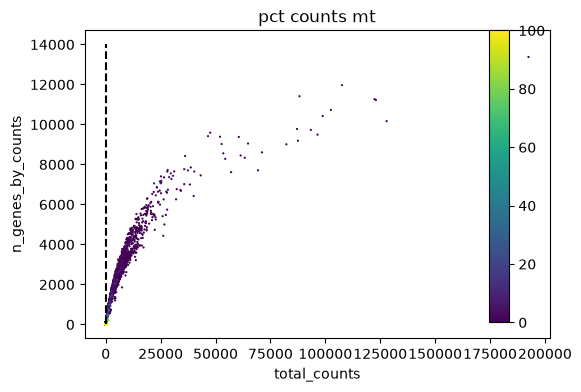

In [62]:
# Number of UMIs (total_counts) and genes detected (n_genes_by_counts)
fig, ax = plt.subplots(1, figsize=(6, 4))
ax.plot([250, 250], [0, 14000], '--k')
sc.pl.scatter(
    step_2_adatas[6178], 
    "total_counts", 
    "n_genes_by_counts", 
    color="pct_counts_mt", 
    ax = ax)

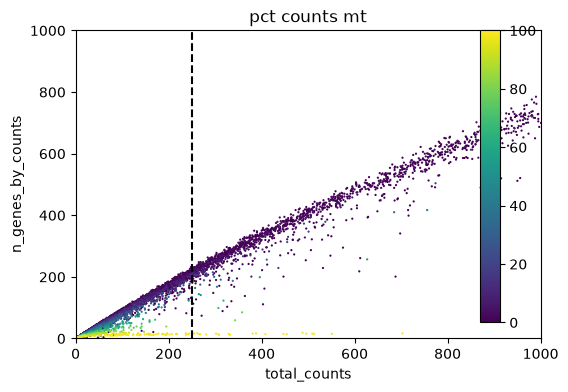

In [61]:
# Zoom in
fig, ax = plt.subplots(1, figsize=(6, 4))
ax.plot([250, 250], [0, 14000], '--k')
ax.set_xlim(0, 1000)
ax.set_ylim(0, 1000)
sc.pl.scatter(step_2_adatas[6178], "total_counts", "n_genes_by_counts", color="pct_counts_mt", ax = ax)


As expected, many of the low-quality nuclei would be removed withy this threshold. However, not all of the nuclei would be removed by this threshold, so it is necessary to add additional QC.

Suppose we want to verify that the QC thresholds we have determined make sense in comparison to the respective parameter distributions. We can call general lists of parameters by calling the `.obs` attribute.

Text(0.5, 1.0, 'Distribution of UMIs/nuclei')

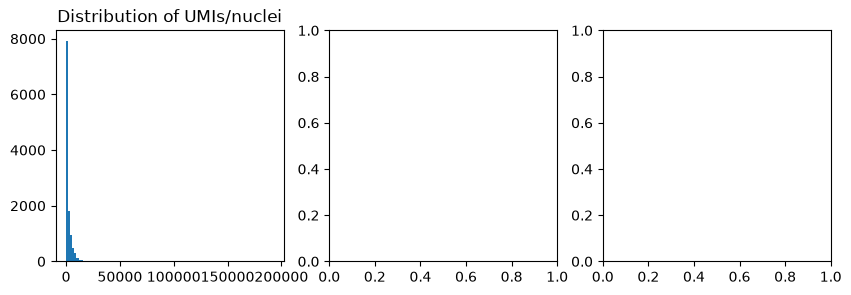

In [ ]:
# Plot as histograms

fig, ax = plt.subplots(1,3, figsize=(10, 3))

# Plot total counts
total_count_list = step_2_adatas[6178].obs['total_counts']
ax[0].hist(total_count_list, bins = 100)
ax[0].set_title('Distribution of UMIs/nuclei')
ax[0].set_ylabel('number of nuclei')
ax[0].plot([250, 250], [0, 8000], '--k')

# Plot per

### rna_filter

### rna_merge

## Modeling

### rna_feature_selection

### rna_model

### rna_latent_transfer

### rna_annotate

### rna_cluster_based_QC